<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/jumping_pendulum_energy_vs_time.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Jumping Pendulum Energy vs Time.

Calculating exact landmark boundaries (u*)...


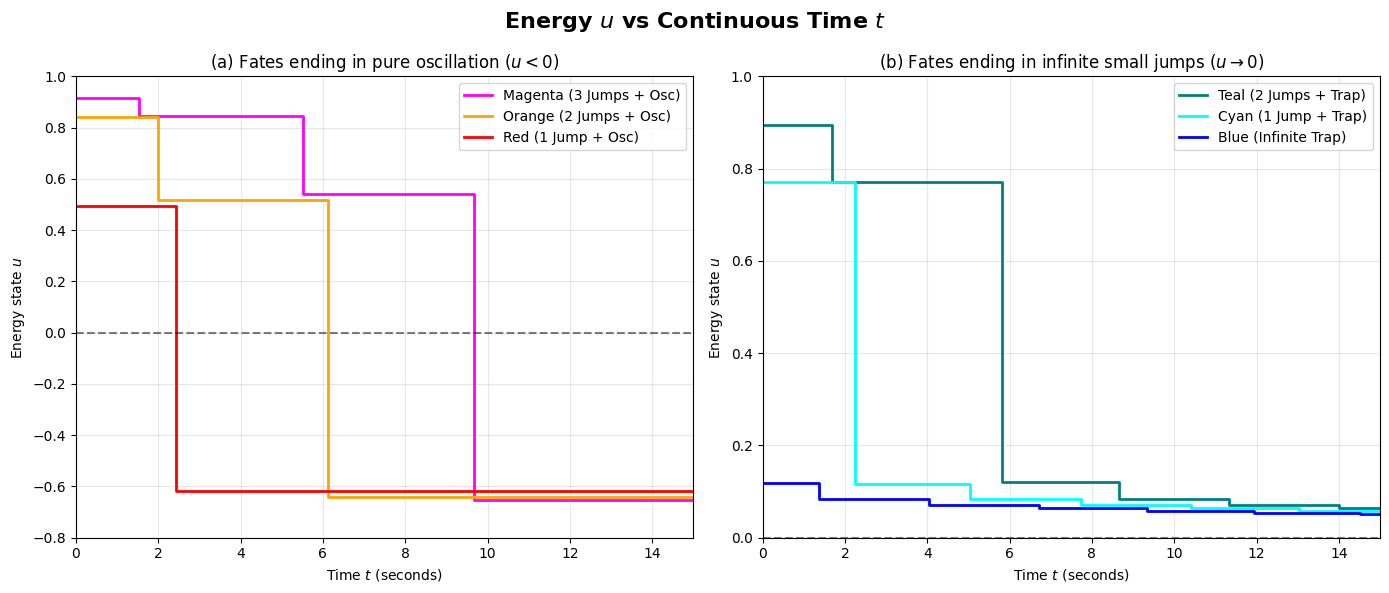

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
from scipy.integrate import quad

# ==========================================
# 1. MATHEMATICAL DEFINITIONS
# ==========================================
def f(u):
    """The exact discrete return map for the jumping pendulum."""
    return u - (64/3) * (u**3) * (1 - u**2)**3

def flight_time(u):
    """Time spent in parabolic freefall (from Section V)."""
    if u <= 0: return 0
    return 4 * np.sqrt(u * (1 - u**2))

def swing_time(u_prev, U_current):
    """
    Time spent swinging on the taut string.
    Requires integrating the energy equation between impact and takeoff angles.
    """
    if U_current <= 0:
        return 0 # If energy is negative, it oscillates forever (no more jumps)

    # Cosine of the impact angle based on the PREVIOUS jump's energy
    cos_theta = u_prev * (4 * u_prev**2 - 3)
    # Clip to avoid floating point errors slightly outside [-1, 1]
    cos_theta = np.clip(cos_theta, -1.0, 1.0)
    alpha_impact = np.arccos(cos_theta)

    # Cosine of the takeoff angle based on the CURRENT energy
    cos_alpha2 = np.clip(U_current, -1.0, 1.0)
    alpha_takeoff = np.arccos(cos_alpha2)

    # The integrand dt = d(alpha) / sqrt(2 + 3U - 2*cos(alpha))
    def integrand(alpha):
        val = 2 + 3*U_current - 2*np.cos(alpha)
        # Prevent division by zero at the exact turning points of pure oscillation
        return 1.0 / np.sqrt(max(val, 1e-9))

    # Integrate from impact down to the bottom (pi), and from the bottom up to takeoff
    t1, _ = quad(integrand, alpha_impact, np.pi)
    t2, _ = quad(integrand, alpha_takeoff, np.pi)

    return t1 + t2

# ==========================================
# 2. FINDING THE EXACT PRE-IMAGES
# ==========================================
print("Calculating exact landmark boundaries (u*)...")
# Find u1* and u2* (roots of f(u) = 0)
u1_star = fsolve(lambda u: f(u), 0.25)[0]
u2_star = fsolve(lambda u: f(u), 0.8)[0]

# Find higher pre-images by running the map backwards
u3_star = fsolve(lambda u: f(u) - u1_star, 0.85)[0]
u4_star = fsolve(lambda u: f(u) - u2_star, 0.95)[0]
u5_star = fsolve(lambda u: f(u) - u3_star, 0.98)[0]
u6_star = fsolve(lambda u: f(u) - u4_star, 0.99)[0]

# Define starting energies as the exact midpoints of the bands
start_conditions = {
    "Blue (Infinite Trap)":     (u1_star / 2, "blue"),
    "Cyan (1 Jump + Trap)":     ((u2_star + u3_star) / 2, "cyan"),
    "Teal (2 Jumps + Trap)":    ((u4_star + u5_star) / 2, "teal"),
    "Red (1 Jump + Osc)":       ((u1_star + u2_star) / 2, "red"),
    "Orange (2 Jumps + Osc)":   ((u3_star + u4_star) / 2, "orange"),
    "Magenta (3 Jumps + Osc)":  ((u5_star + u6_star) / 2, "magenta")
}

# ==========================================
# 3. SIMULATING REAL CONTINUOUS TIME
# ==========================================
def simulate_trajectory(u0, max_jumps=15, time_cap=15.0):
    t_history = [0.0]
    u_history = [u0]

    current_t = 0.0
    current_u = u0

    for n in range(max_jumps):
        if current_u <= 0:
            # Pendulum is trapped in pure oscillation.
            # Energy is conserved from here on out.
            t_history.append(current_t + time_cap)
            u_history.append(current_u)
            break

        # 1. The Flight Phase (Energy remains constant)
        tf = flight_time(current_u)
        current_t += tf
        t_history.append(current_t)
        u_history.append(current_u)

        # 2. The Impact! (Energy instantly drops)
        next_u = f(current_u)
        t_history.append(current_t)
        u_history.append(next_u)

        if next_u <= 0:
            current_u = next_u
            continue # Let the loop catch the oscillation phase next iteration

        # 3. The Swing Phase (Energy remains constant at new value)
        tp = swing_time(current_u, next_u)
        current_t += tp
        t_history.append(current_t)
        u_history.append(next_u)

        current_u = next_u

    return t_history, u_history

# ==========================================
# 4. PLOTTING THE RESULTS
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
plt.suptitle("Energy $u$ vs Continuous Time $t$", fontsize=16, fontweight='bold')

# Panel A: Oscillation Fates
for name in ["Magenta (3 Jumps + Osc)", "Orange (2 Jumps + Osc)", "Red (1 Jump + Osc)"]:
    u0, color = start_conditions[name]
    t_hist, u_hist = simulate_trajectory(u0)
    ax1.plot(t_hist, u_hist, color=color, linewidth=2, label=name)

ax1.set_title("(a) Fates ending in pure oscillation ($u < 0$)")
ax1.set_xlabel("Time $t$ (seconds)")
ax1.set_ylabel("Energy state $u$")
ax1.axhline(0, color='black', linestyle='--', alpha=0.5)
ax1.set_xlim(0, 15)
ax1.set_ylim(-0.8, 1.0)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Panel B: Infinite Trap Fates
for name in ["Teal (2 Jumps + Trap)", "Cyan (1 Jump + Trap)", "Blue (Infinite Trap)"]:
    u0, color = start_conditions[name]
    t_hist, u_hist = simulate_trajectory(u0, max_jumps=15)
    ax2.plot(t_hist, u_hist, color=color, linewidth=2, label=name)

ax2.set_title("(b) Fates ending in infinite small jumps ($u \\to 0$)")
ax2.set_xlabel("Time $t$ (seconds)")
ax2.set_ylabel("Energy state $u$")
ax2.axhline(0, color='black', linestyle='--', alpha=0.5)
ax2.set_xlim(0, 15)
ax2.set_ylim(0, 1.0)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()